Feature matrix shape: (569, 30)
Target vector shape: (569,)
Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}
target
1    357
0    212
Name: count, dtype: int64


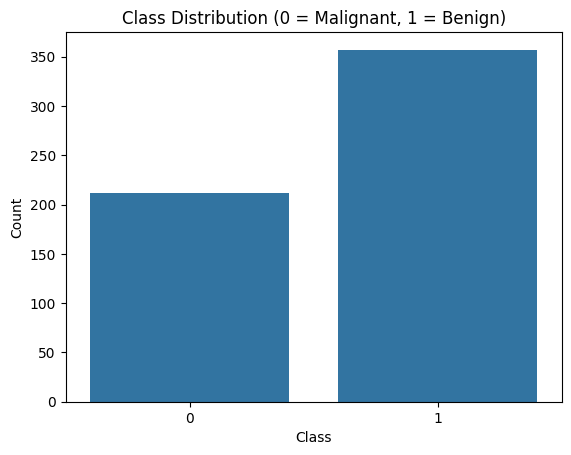

Total missing values: 0
Data types:
 float64    30
Name: count, dtype: int64
Any missing values: False
Training samples: 455
Testing samples: 114
Mean of scaled training data (approx 0): -0.0
Std of scaled training data (approx 1): 1.0
{'n_estimators': 100, 'max_depth': 4} -> mean CV accuracy: 0.9516
{'n_estimators': 200, 'max_depth': 6} -> mean CV accuracy: 0.956
{'n_estimators': 300, 'max_depth': None} -> mean CV accuracy: 0.9582

Selected hyperparameters: {'n_estimators': 300, 'max_depth': None}
Random Forest training complete.
AdaBoost cross-validation accuracy scores: [0.967  0.989  0.9341 0.978  0.989 ]
Mean cross-validation accuracy: 0.9714


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Neural network training complete.


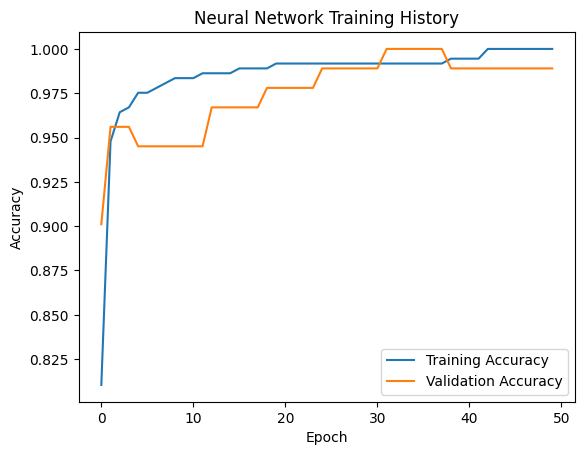

Predictions generated for Random Forest, AdaBoost and the neural network.


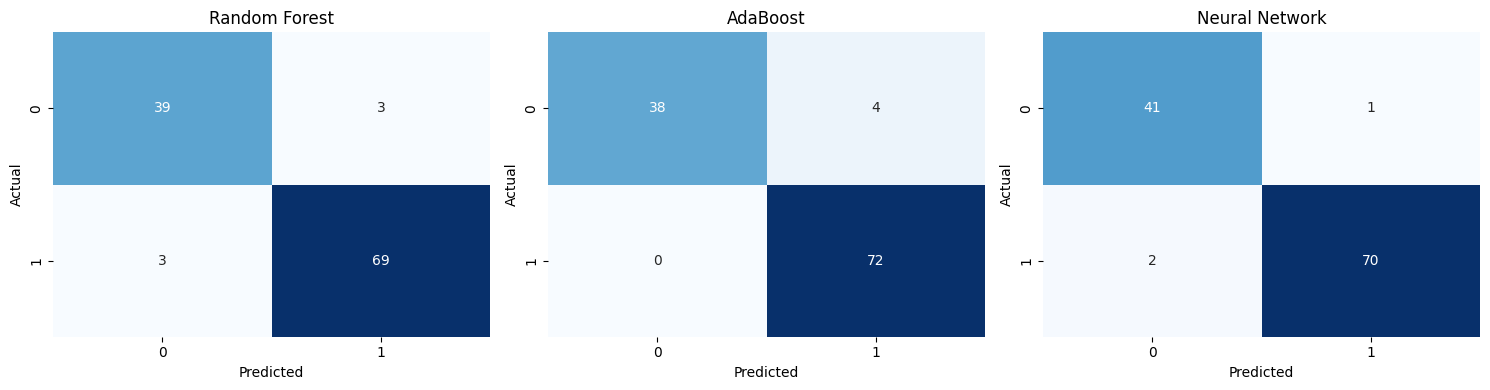

                                   Accuracy  Precision  Recall  F1-score
Model                                                                   
Random Forest                        0.9474     0.9583  0.9583    0.9583
AdaBoost                             0.9649     0.9474  1.0000    0.9730
Neural Network (TensorFlow/Keras)    0.9737     0.9859  0.9722    0.9790


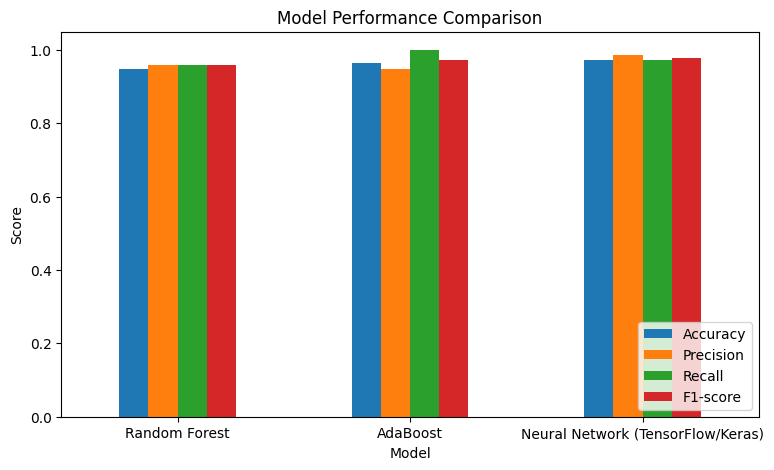

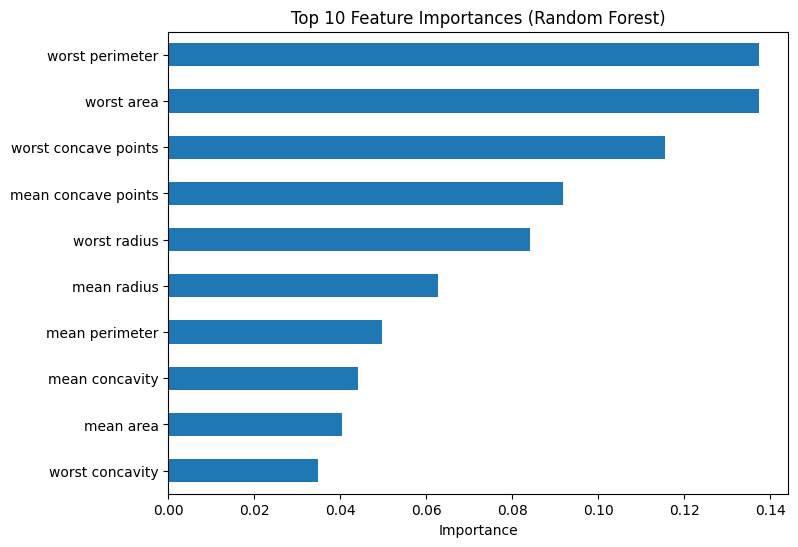

worst perimeter         0.137344
worst area              0.137312
worst concave points    0.115502
mean concave points     0.091774
worst radius            0.084111
mean radius             0.062741
mean perimeter          0.049680
mean concavity          0.044142
mean area               0.040508
worst concavity         0.034837
dtype: float64


In [3]:
# The complete, executable Python code used in this experiment is given below.
# ---- Implement Random Forest and AdaBoost Algorithms and Compare Their Performance ----
# ---- Aim ----
# ---- Introduction ----
# ---- Objectives ----
# ---- Required Libraries ----
# ---- Dataset Description ----
# ---- Import Libraries ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
f1_score, confusion_matrix, classification_report)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
# Set random seeds so that results are reasonably reproducible
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
# ---- Load Dataset ----
# Load the Breast Cancer Wisconsin dataset directly from scikit-learn
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Class labels:", dict(enumerate(dataset.target_names)))
# ---- Explore Dataset ----
# Look at the first few rows of the feature data
X.head()
# Basic statistical summary of the features
X.describe()
# Check the class balance of the target variable
print(y.value_counts())
sns.countplot(x=y)
plt.title("Class Distribution (0 = Malignant, 1 = Benign)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()
# Check for missing values in the dataset
print("Total missing values:", X.isnull().sum().sum())
# ---- Data Preprocessing ----
# Confirm there are no categorical columns and no missing values
print("Data types:\n", X.dtypes.value_counts())
print("Any missing values:", X.isnull().values.any())
# ---- Train-Test Split ----
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
# ---- Feature Scaling ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)
print("Mean of scaled training data (approx 0):", np.round(X_train_scaled.mean(), 3))
print("Std of scaled training data (approx 1):", np.round(X_train_scaled.std(), 3))
# ---- Random Forest Implementation ----
# Simple hyperparameter selection using cross-validation
param_options = [
{"n_estimators": 100, "max_depth": 4},
{"n_estimators": 200, "max_depth": 6},
{"n_estimators": 300, "max_depth": None},
]
best_score = 0
best_params = None
for params in param_options:
    candidate = RandomForestClassifier(random_state=RANDOM_SEED, **params)
    scores = cross_val_score(candidate, X_train, y_train, cv=5)
    print(params, "-> mean CV accuracy:", round(scores.mean(), 4))
    if scores.mean() > best_score:
        best_score = scores.mean()
        best_params = params
print("\nSelected hyperparameters:", best_params)
# Train the final Random Forest model with the selected hyperparameters
rf_model = RandomForestClassifier(random_state=RANDOM_SEED, **best_params)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest training complete.")
# ---- AdaBoost Implementation ----
# AdaBoost with decision stumps (max_depth = 1) as the weak learner
ada_model = AdaBoostClassifier(
estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED),
n_estimators=200,
learning_rate=1.0,
random_state=RANDOM_SEED
)
ada_model.fit(X_train, y_train)
ada_pred = ada_model.predict(X_test)
# Cross-validation gives a more reliable estimate of AdaBoost performance than a single split
ada_cv_scores = cross_val_score(ada_model, X_train, y_train, cv=5)
print("AdaBoost cross-validation accuracy scores:", np.round(ada_cv_scores, 4))
print("Mean cross-validation accuracy:", round(ada_cv_scores.mean(), 4))
# ---- TensorFlow/Keras Neural Network Implementation ----
# Build a simple Sequential neural network for binary classification
keras_model = keras.Sequential([
layers.Input(shape=(X_train_scaled.shape[1],)),
layers.Dense(32, activation="relu"),
layers.Dense(16, activation="relu"),
layers.Dense(1, activation="sigmoid")
])
# Compile the model with an appropriate loss function and optimizer
keras_model.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)
keras_model.summary()
# ---- Model Training ----
history = keras_model.fit(
X_train_scaled, y_train,
validation_split=0.2,
epochs=50,
batch_size=16,
verbose=0
)
print("Neural network training complete.")
# Plot training and validation accuracy across epochs
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network Training History")
plt.legend()
plt.show()
# ---- Model Prediction ----
# Generate predictions from the neural network on the test set
keras_prob = keras_model.predict(X_test_scaled, verbose=0)
keras_pred = (keras_prob > 0.5).astype(int).flatten()
print("Predictions generated for Random Forest, AdaBoost and the neural network.")
# ---- Model Evaluation ----
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred)
    }
results = [
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("AdaBoost", y_test, ada_pred),
    evaluate_model("Neural Network (TensorFlow/Keras)", y_test, keras_pred),
]
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)
# ---- Confusion Matrices ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
predictions = {"Random Forest": rf_pred, "AdaBoost": ada_pred, "Neural Network": keras_pred}
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()
# ---- Performance Comparison ----
# Display the comparison table
print(results_df.round(4))
# Plot the comparison as a bar chart
results_df.plot(kind="bar", figsize=(9, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()
# ---- Feature Importance ----
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(10)
top_features.plot(kind="barh", figsize=(8, 6))
plt.gca().invert_yaxis()
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.show()
print(top_features)
# ---- Interpretation of Results ----
# ---- Conclusion ----